In [1]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# data folder se sari MRI images dhoondhna
data_folder = Path("../data")

image_files = (
    list(data_folder.rglob("*.jpg")) +
    list(data_folder.rglob("*.jpeg")) +
    list(data_folder.rglob("*.png"))
)

print("Total MRI images:", len(image_files))
print("1st image path:", image_files[0])

Total MRI images: 253
1st image path: ..\data\no\10 no.jpg


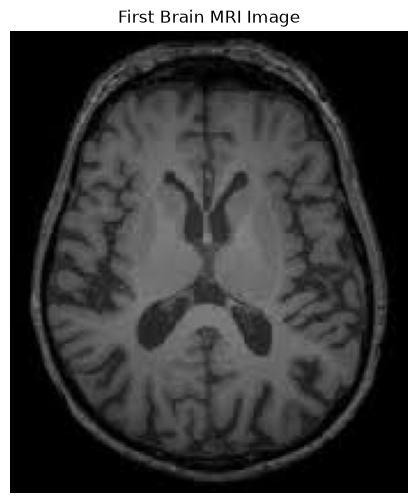

In [3]:
img = Image.open(image_files[0])

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.title("First Brain MRI Image")
plt.axis("off")
plt.show()

Tumor images: 155
No-tumor images: 98


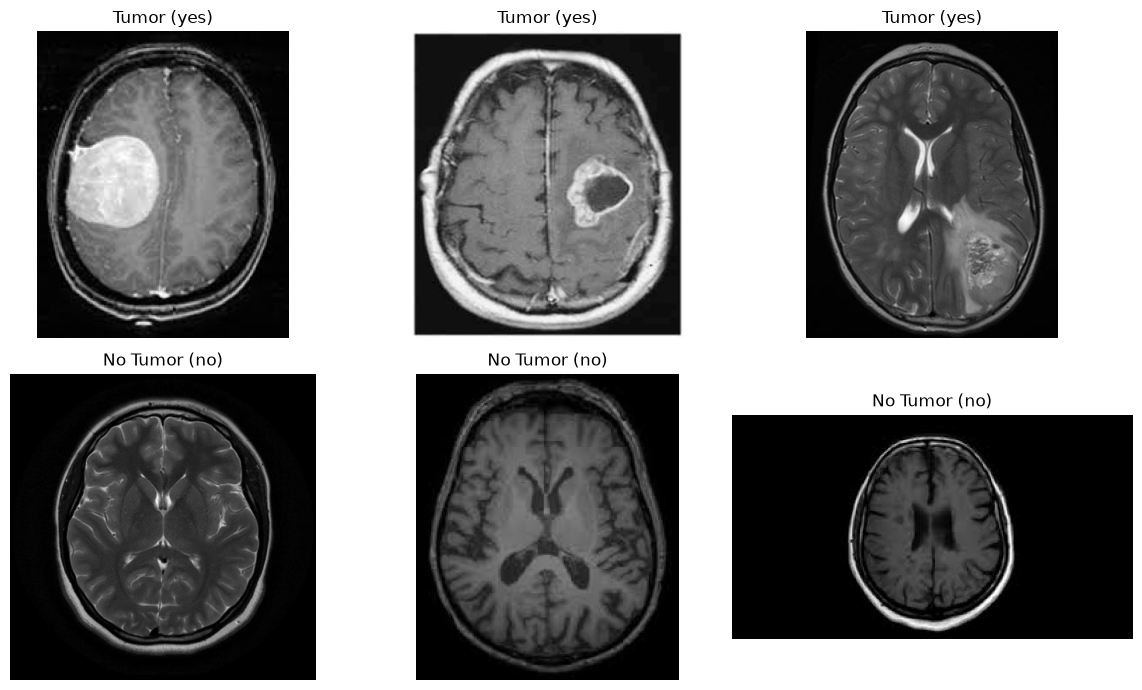

In [3]:
yes_folder = next(data_folder.rglob("yes"))
no_folder = next(data_folder.rglob("no"))

yes_images = list(yes_folder.glob("*"))
no_images = list(no_folder.glob("*"))

print("Tumor images:", len(yes_images))
print("No-tumor images:", len(no_images))

plt.figure(figsize=(12, 7))

# Pehli row: tumor images
for i, file in enumerate(yes_images[:3]):
    img = Image.open(file)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("Tumor (yes)")
    plt.axis("off")

# Doosri row: no-tumor images
for i, file in enumerate(no_images[:3]):
    img = Image.open(file)
    plt.subplot(2, 3, i + 4)
    plt.imshow(img, cmap="gray")
    plt.title("No Tumor (no)")
    plt.axis("off")

plt.tight_layout()
plt.show()

Original pixel range: 0 to 255
Normalized pixel range: 0.0 to 1.0


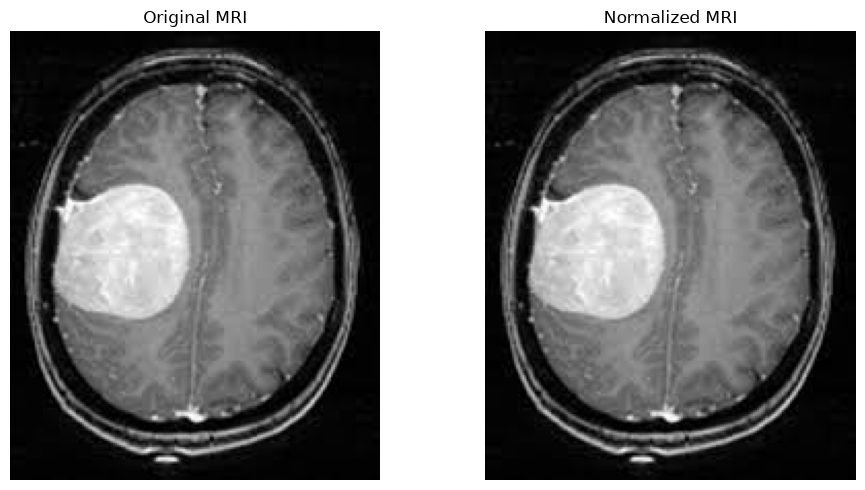

In [4]:
import numpy as np

# Ek tumor-category MRI select karein
img = Image.open(yes_images[0]).convert("L")  # L = grayscale
img_array = np.array(img)

# Normalization
normalized_img = img_array / 255.0

print("Original pixel range:", img_array.min(), "to", img_array.max())
print("Normalized pixel range:", normalized_img.min(), "to", normalized_img.max())

# Original aur normalized image compare karein
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array, cmap="gray", vmin=0, vmax=255)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalized_img, cmap="gray", vmin=0, vmax=1)
plt.title("Normalized MRI")
plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import cv2
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


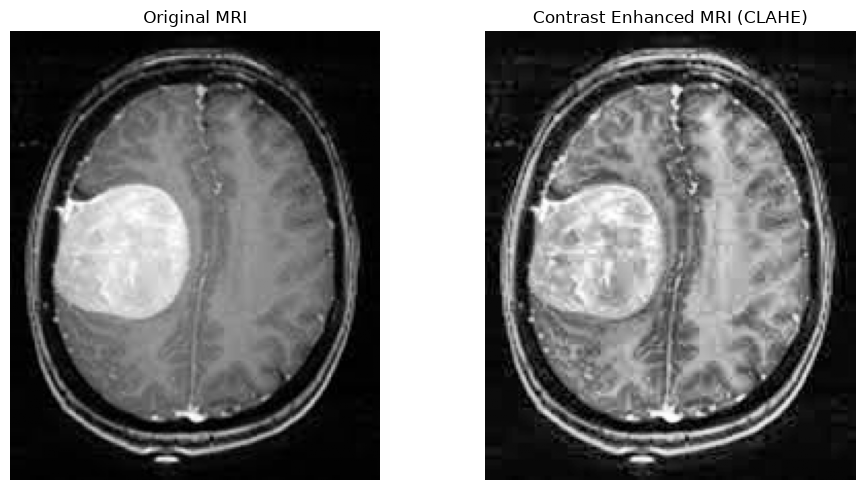

In [3]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Tumor folder aur uski pehli MRI image dhoondhein
data_folder = Path("../data")
yes_folder = next(data_folder.rglob("yes"))

image_files = (
    list(yes_folder.glob("*.jpg")) +
    list(yes_folder.glob("*.jpeg")) +
    list(yes_folder.glob("*.png"))
)

# Image ko grayscale array mein convert karein
img = Image.open(image_files[0]).convert("L")
img_array = np.array(img)

# Contrast enhancement (CLAHE)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced_img = clahe.apply(img_array)

# Comparison
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_img, cmap="gray")
plt.title("Contrast Enhanced MRI (CLAHE)")
plt.axis("off")

plt.tight_layout()
plt.show()

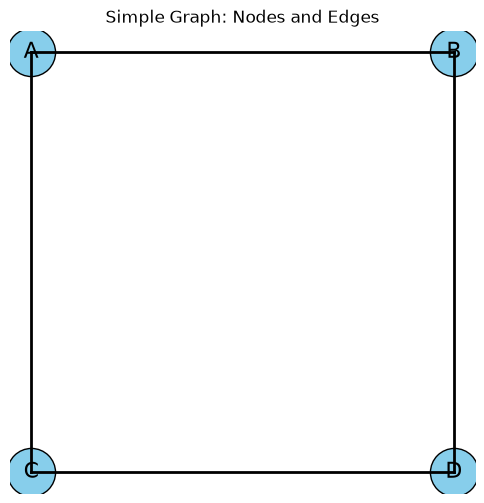

In [4]:
import matplotlib.pyplot as plt

# 4 nodes ki positions
nodes = {
    "A": (0, 1),
    "B": (1, 1),
    "C": (0, 0),
    "D": (1, 0)
}

# Nodes ke connections (edges)
edges = [("A", "B"), ("A", "C"), ("B", "D"), ("C", "D")]

plt.figure(figsize=(6, 6))

# Edges draw karein
for start, end in edges:
    x1, y1 = nodes[start]
    x2, y2 = nodes[end]
    plt.plot([x1, x2], [y1, y2], "black", linewidth=2)

# Nodes draw aur label karein
for label, (x, y) in nodes.items():
    plt.scatter(x, y, s=1200, color="skyblue", edgecolor="black")
    plt.text(x, y, label, ha="center", va="center", fontsize=16)

plt.title("Simple Graph: Nodes and Edges")
plt.axis("off")
plt.show()

[[0 1 1 0]
 [1 0 0 1]
 [1 0 0 1]
 [0 1 1 0]]


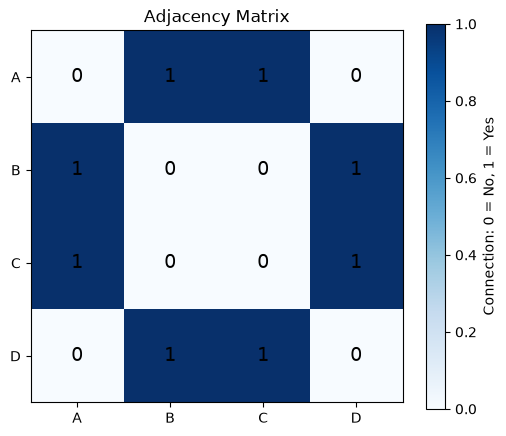

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Node order: A, B, C, D
adjacency_matrix = np.array([
    [0, 1, 1, 0],  # A is connected to B and C
    [1, 0, 0, 1],  # B is connected to A and D
    [1, 0, 0, 1],  # C is connected to A and D
    [0, 1, 1, 0]   # D is connected to B and C
])

print(adjacency_matrix)

plt.figure(figsize=(6, 5))
plt.imshow(adjacency_matrix, cmap="Blues")

plt.xticks([0, 1, 2, 3], ["A", "B", "C", "D"])
plt.yticks([0, 1, 2, 3], ["A", "B", "C", "D"])

for i in range(4):
    for j in range(4):
        plt.text(j, i, adjacency_matrix[i, j],
                 ha="center", va="center", fontsize=14)

plt.title("Adjacency Matrix")
plt.colorbar(label="Connection: 0 = No, 1 = Yes")
plt.show()

In [6]:
import numpy as np

# Har node ka initial feature
features = np.array([2, 4, 6, 8], dtype=float)

# Adjacency matrix: A, B, C, D
A = np.array([
    [0, 1, 1, 0],
    [1, 0, 0, 1],
    [1, 0, 0, 1],
    [0, 1, 1, 0]
], dtype=float)

# Self-loops: har node apni information bhi retain kare
A_with_self_loops = A + np.eye(4)

# Har node ke total connections
degrees = A_with_self_loops.sum(axis=1)

# Node + neighbors ka average feature
new_features = A_with_self_loops @ features / degrees

print("Original features:", features)
print("GCN ke baad features:", new_features)

Original features: [2. 4. 6. 8.]
GCN ke baad features: [4.         4.66666667 5.33333333 6.        ]


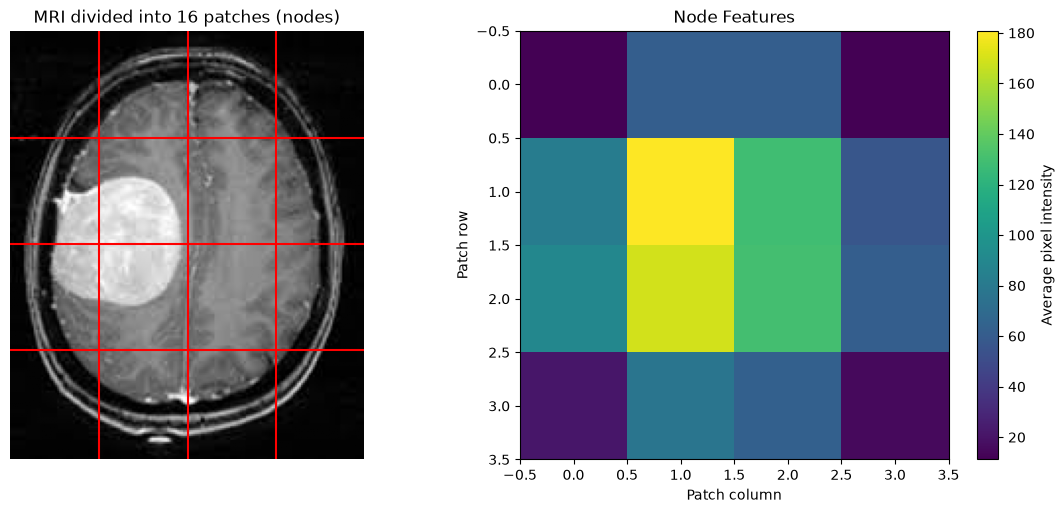

In [7]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Ek tumor MRI image load karein
data_folder = Path("../data")
yes_folder = next(data_folder.rglob("yes"))
first_image = list(yes_folder.glob("*"))[0]

img = Image.open(first_image).convert("L")
img_array = np.array(img)

# MRI ko 4 x 4 patches mein divide karein
rows, cols = 4, 4
height, width = img_array.shape
patch_h = height // rows
patch_w = width // cols

# Har patch ki mean intensity = node feature
node_features = np.zeros((rows, cols))

for r in range(rows):
    for c in range(cols):
        patch = img_array[
            r * patch_h:(r + 1) * patch_h,
            c * patch_w:(c + 1) * patch_w
        ]
        node_features[r, c] = patch.mean()

# Original MRI par patch-grid draw karein
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array, cmap="gray")
for r in range(1, rows):
    plt.axhline(r * patch_h, color="red")
for c in range(1, cols):
    plt.axvline(c * patch_w, color="red")
plt.title("MRI divided into 16 patches (nodes)")
plt.axis("off")

# Node features ko heatmap mein show karein
plt.subplot(1, 2, 2)
plt.imshow(node_features, cmap="viridis")
plt.colorbar(label="Average pixel intensity")
plt.title("Node Features")
plt.xlabel("Patch column")
plt.ylabel("Patch row")

plt.tight_layout()
plt.show()

Adjacency matrix size: (16, 16)
Total edges: 24


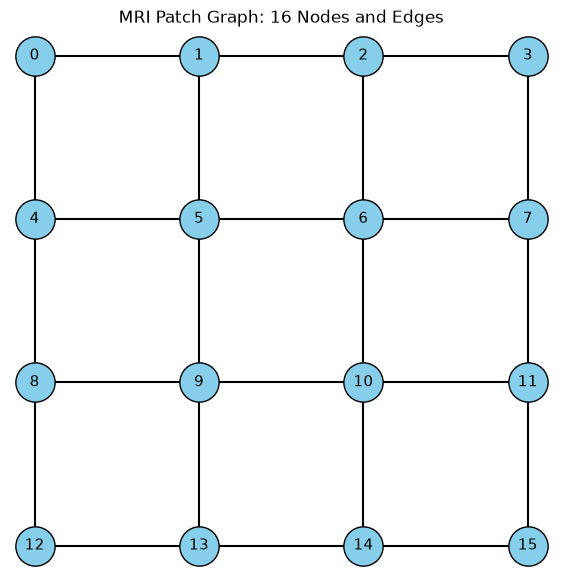

In [8]:
import numpy as np
import matplotlib.pyplot as plt

rows, cols = 4, 4
num_nodes = rows * cols

# 16 × 16 adjacency matrix
A = np.zeros((num_nodes, num_nodes), dtype=int)

# Grid mein adjacent nodes ko connect karein
for r in range(rows):
    for c in range(cols):
        node = r * cols + c

        # Right neighbor
        if c < cols - 1:
            right = r * cols + (c + 1)
            A[node, right] = 1
            A[right, node] = 1

        # Bottom neighbor
        if r < rows - 1:
            bottom = (r + 1) * cols + c
            A[node, bottom] = 1
            A[bottom, node] = 1

print("Adjacency matrix size:", A.shape)
print("Total edges:", A.sum() // 2)

# Graph draw karein
plt.figure(figsize=(7, 7))

for r in range(rows):
    for c in range(cols):
        node = r * cols + c
        x, y = c, -r

        # Right edge
        if c < cols - 1:
            plt.plot([x, x + 1], [y, y], "black")

        # Bottom edge
        if r < rows - 1:
            plt.plot([x, x], [y, y - 1], "black")

        # Node
        plt.scatter(x, y, s=800, color="skyblue", edgecolor="black", zorder=2)
        plt.text(x, y, str(node), ha="center", va="center", fontsize=11)

plt.title("MRI Patch Graph: 16 Nodes and Edges")
plt.axis("off")
plt.show()

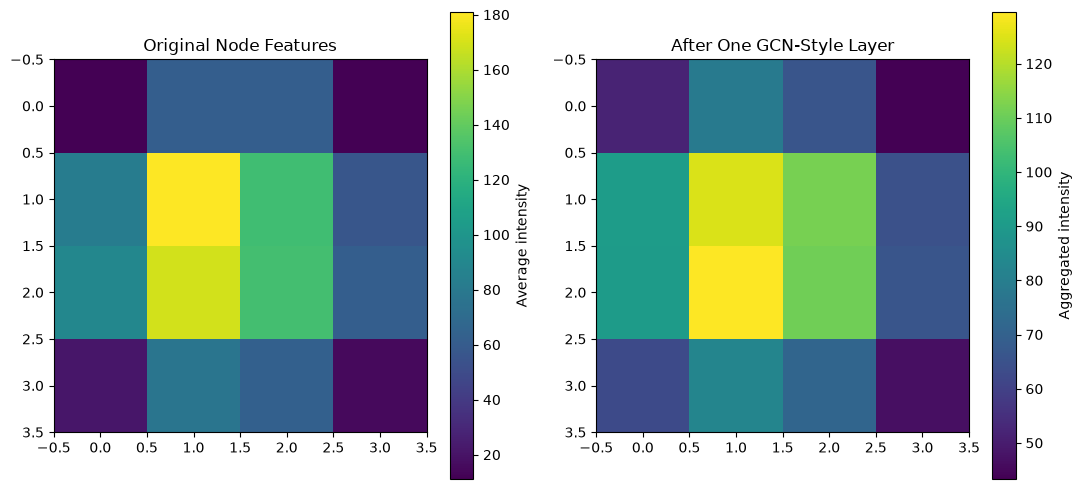

In [9]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 1) Ek MRI image load karein
data_folder = Path("../data")
yes_folder = next(data_folder.rglob("yes"))
img = Image.open(list(yes_folder.glob("*"))[0]).convert("L")
img_array = np.array(img)

# 2) MRI ko 4 × 4 patches (16 nodes) mein split karein
rows, cols = 4, 4
height, width = img_array.shape
patch_h, patch_w = height // rows, width // cols

node_features = np.zeros((rows, cols))

for r in range(rows):
    for c in range(cols):
        patch = img_array[
            r * patch_h:(r + 1) * patch_h,
            c * patch_w:(c + 1) * patch_w
        ]
        node_features[r, c] = patch.mean()

features = node_features.flatten()

# 3) Adjacent patches ka graph / adjacency matrix banayein
num_nodes = rows * cols
A = np.zeros((num_nodes, num_nodes))

for r in range(rows):
    for c in range(cols):
        node = r * cols + c

        if c < cols - 1:  # right neighbor
            right = node + 1
            A[node, right] = A[right, node] = 1

        if r < rows - 1:  # bottom neighbor
            bottom = node + cols
            A[node, bottom] = A[bottom, node] = 1

# 4) GCN-style aggregation: self-loop + neighbor average
A_self = A + np.eye(num_nodes)
degrees = A_self.sum(axis=1)
gcn_features = (A_self @ features) / degrees

# 5) Before vs. after comparison
plt.figure(figsize=(11, 5))

plt.subplot(1, 2, 1)
plt.imshow(node_features, cmap="viridis")
plt.colorbar(label="Average intensity")
plt.title("Original Node Features")

plt.subplot(1, 2, 2)
plt.imshow(gcn_features.reshape(rows, cols), cmap="viridis")
plt.colorbar(label="Aggregated intensity")
plt.title("After One GCN-Style Layer")

plt.tight_layout()
plt.show()